#### Extraction of node embeddings

In [1]:
import torch
import matplotlib.pyplot as plt
import networkx as nx
from torch_geometric.nn import Node2Vec
from torch_geometric.utils import from_networkx

In [2]:
G = nx.read_gexf("../graph.gexf", node_type=int)

print(f"# nodes: {G.number_of_nodes()}")
print(f"# ndges: {G.number_of_edges()}")

# nodes: 2464
# ndges: 3695


In [ ]:
no_feats_G = nx.Graph(list(G.edges()))

data = from_networkx(no_feats_G)

In [4]:
model = Node2Vec(
    data.edge_index,
    embedding_dim=64,
    walk_length=20,
    context_size=10,
    walks_per_node=10,
    num_negative_samples=1,
    p=1,  
    q=1,  
    sparse=True,
)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = model.to(device)

loader = model.loader(batch_size=128, shuffle=True, num_workers=0)
optimizer = torch.optim.SparseAdam(list(model.parameters()), lr=0.01)

def train():
    model.train()
    total_loss = 0
    for pos_rw, neg_rw in loader:
        optimizer.zero_grad()
        loss = model.loss(pos_rw.to(device), neg_rw.to(device))
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)

In [5]:
losses = []

for epoch in range(1, 51):
    loss = train()
    losses.append(loss)
    if epoch % 10 == 0:
        print(f'Epoch: {epoch:03d}, Loss: {loss:.4f}')

Epoch: 010, Loss: 1.3260
Epoch: 020, Loss: 0.8697
Epoch: 030, Loss: 0.7899
Epoch: 040, Loss: 0.7646
Epoch: 050, Loss: 0.7540


In [6]:
model.eval()
embeddings = model.embedding.weight.data.cpu()

In [7]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

pca = PCA(n_components=2)
tsne = TSNE(n_components=2)

pca_embs2d = pca.fit_transform(embeddings)
tsne_embs2d = tsne.fit_transform(embeddings)

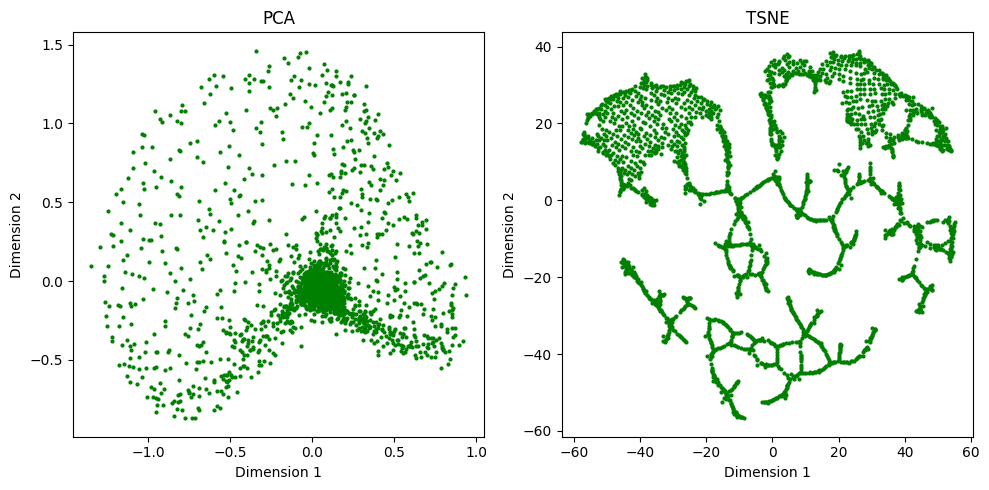

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5)) 

axes[0].scatter(pca_embs2d[:, 0], pca_embs2d[:, 1], s=4, color="green")
axes[0].set_title('PCA')
axes[0].set_xlabel('Dimension 1')
axes[0].set_ylabel('Dimension 2')

axes[1].scatter(tsne_embs2d[:, 0], tsne_embs2d[:, 1], s=4, color="green")
axes[1].set_title('TSNE')
axes[1].set_xlabel('Dimension 1')
axes[1].set_ylabel('Dimension 2')

plt.tight_layout()
plt.show()

#### These embeddings now can be used for downstream tasks such as traffic prediction